# Modelo predictivo GPR
En este markdown se va a realizar el entrenamiento de un modelo predictivo con la finalidad de estimar qué consumo energético se realizará por parte de la UPV (Universidad Politécnica de Valencai) en los próximos años.

## Introducción

Para llevar a cabo el modelo se va a utilizar los datos pertenecientes a un registro histórico que va desde 2012 hasta 2025 del consumo energético en esta universidad. Estos datos primero se cargaran y prepararán para dicho entrenamiento, separandose entre train y test (dos últimos años registrados). El entrenamiento se realizara sobre 3 modelos diferentes los cuales se pondrán a prueba para ver cúal obtiene unos mejores resultados. Una vez se elija el mejor de los tres modelos se reentrenará con la muestra completa y se guardará el modelo, para su uso en la aplicación web desarrollada por el equipo.

## Cargar datos
A continuación se va a realizar la carga de datos y un par de visualizaciones.

In [55]:
import pandas as pd

df = pd.read_excel("datos_energia_combinado.xlsx")

df.head()

,Uni,Año,Enero,Febrero,Marzo,Abril,Mayo,Junio,Julio,Agosto,Septiembre,Octubre,Noviembre,Diciembre,Total
0,UPM,2015,3635911.0,3665181.0,3351735.0,2813039.0,2978351.0,3298865.0,3744984.0,2534919.0,2895668.0,2876937.0,3019513.0,3372108.0,38187211.0
1,UPM,2016,3495966.0,3296022.0,3164978.0,2989215.0,2888346.0,3174476.0,6042782.0,2256082.0,3122770.0,2723927.0,2816669.0,198157.0,36169390.0
2,UPM,2017,2863325.0,2670652.0,3049086.0,2514610.0,2848144.0,3119557.0,3019128.0,2350478.0,2762599.0,2886533.0,2958967.0,2964181.0,34007260.0
3,UPM,2018,3015546.0,3169453.0,3026652.0,2851836.0,2837233.0,2945040.0,3097799.0,2206893.0,3085272.0,2727866.0,2963613.0,2930680.0,34857883.0
4,UPM,2019,2940087.0,2823582.0,2705160.0,2508439.0,2566246.0,2731224.0,3842601.0,2338257.0,2937132.0,3151676.0,3275462.0,3034822.0,34854688.0


In [56]:
df

,Uni,Año,Enero,Febrero,Marzo,Abril,Mayo,Junio,Julio,Agosto,Septiembre,Octubre,Noviembre,Diciembre,Total
0,UPM,2015,3635911.0,3665181.0,3351735.0,2813039.0,2978351.0,3298865.0,3744984.0,2534919.00,2895668.00,2876937.0,3019513.0,3372108.0,38187211.00
1,UPM,2016,3495966.0,3296022.0,3164978.0,2989215.0,2888346.0,3174476.0,6042782.0,2256082.00,3122770.00,2723927.0,2816669.0,198157.0,36169390.00
2,UPM,2017,2863325.0,2670652.0,3049086.0,2514610.0,2848144.0,3119557.0,3019128.0,2350478.00,2762599.00,2886533.0,2958967.0,2964181.0,34007260.00
3,UPM,2018,3015546.0,3169453.0,3026652.0,2851836.0,2837233.0,2945040.0,3097799.0,2206893.00,3085272.00,2727866.0,2963613.0,2930680.0,34857883.00
4,UPM,2019,2940087.0,2823582.0,2705160.0,2508439.0,2566246.0,2731224.0,3842601.0,2338257.00,2937132.00,3151676.0,3275462.0,3034822.0,34854688.00
5,UPM,2020,3408429.0,3462883.0,2323416.0,1653222.0,1741441.0,1975406.0,2454131.0,2126606.00,2166357.00,2249406.0,1761696.0,26704.0,25349697.00
6,UPM,2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26956373.00
7,UPM,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28086155.00
8,UPV,2012,4728443.0,5052172.0,4614467.0,3824308.0,4851124.0,5862283.0,6204754.0,3989134.00,5193306.00,4552792.0,4261599.0,5045506.0,58179888.00
9,UPV,2013,4513735.0,4411422.0,4217935.0,3808360.0,4279468.0,4716192.0,5716148.0,3136826.07,5095234.59,4975378.0,4181810.0,4034277.0,53086785.66


## Dividir datos entre train y test
Los datos que se van a utilizar tienen la información de varias universidades. En este caso solo se pretende realizar el modelo predictivo sobre los datos pertenecientes a la UPV (Universidad Politécnica de Valencia). Primero se va a filtrar el data frame para solo quedarnos con los datos pertenecientes a la UPV.

In [37]:
df_upv = df[df['Uni'] == 'UPV']
df_upv

,Uni,Año,Enero,Febrero,Marzo,Abril,Mayo,Junio,Julio,Agosto,Septiembre,Octubre,Noviembre,Diciembre,Total
8,UPV,2012,4728443.0,5052172.0,4614467.0,3824308.0,4851124.0,5862283.0,6204754.0,3989134.00,5193306.00,4552792.0,4261599.0,5045506.0,58179888.00
9,UPV,2013,4513735.0,4411422.0,4217935.0,3808360.0,4279468.0,4716192.0,5716148.0,3136826.07,5095234.59,4975378.0,4181810.0,4034277.0,53086785.66
10,UPV,2014,4152692.0,4031112.0,3851104.0,3541607.0,4023995.0,4680210.0,5149151.0,3123758.00,5327604.00,4575325.0,3612554.0,3761594.0,49830706.00
11,UPV,2015,3991185.0,4004701.0,3816891.0,3283246.0,4108610.0,4700501.0,5645792.0,2916524.00,4410320.00,3713096.0,3542806.0,3532262.0,47665934.00
12,UPV,2016,3494170.0,3568190.0,3374739.0,3246281.0,3473490.0,4359323.0,4641373.0,2670503.00,4595327.00,3794865.0,3513803.0,3521488.0,44253552.00
13,UPV,2017,4098067.0,3415662.0,3467650.0,2747283.0,3633069.0,4611322.0,3676903.0,2545828.00,4054094.00,3754484.0,3345028.0,3377261.0,42726651.00
14,UPV,2018,3418488.0,3553878.0,3360081.0,2879248.0,3318829.0,4019563.0,4680821.0,2622237.00,4168621.00,3472942.0,3295895.0,3143310.0,41933913.00
15,UPV,2019,3595234.0,3340028.0,3091357.0,2872033.0,3299514.0,3660018.0,4708458.0,2461301.00,3808563.00,3633364.0,3234905.0,3171335.0,40876110.00
16,UPV,2020,3623148.0,3222688.0,2581647.0,1819617.0,2051602.0,2459941.0,3896564.0,2455666.00,3594340.00,2944276.0,3082785.0,3158284.0,34890558.00
17,UPV,2021,3288826.0,2841453.0,3308567.0,2970072.0,3102367.0,3803461.0,4357697.0,2508123.00,4260782.00,3328730.0,3309979.0,2689846.0,39769903.00



Para usar Prophet, SARIMAX y XGBoost, transformamos el DataFrame para tener como filas los valores de energía correspondientes de cada año y cada mes.

In [57]:
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo ','Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

df_long = pd.melt(
    df_upv,
    id_vars=['Año'],
    value_vars=meses,
    var_name='Mes',
    value_name='Energia'
)
df_long

,Año,Mes,Energia
0,2012,Enero,4728443.0
1,2013,Enero,4513735.0
2,2014,Enero,4152692.0
3,2015,Enero,3991185.0
4,2016,Enero,3494170.0
...,...,...,...
163,2021,Diciembre,2689846.0
164,2022,Diciembre,2981709.0
165,2023,Diciembre,3051458.0
166,2024,Diciembre,4482190.0


Ahora dividimos el dataset en **Train** (por ejemplo, datos hasta el año 2023) y **Test** (años 2024 y 2025) para validar correctamente los modelos de series temporales.

In [58]:
# 1. Limpiar espacios en los nombres de los meses y mapear a números
df_long['Mes'] = df_long['Mes'].str.strip()
meses_dict = {
    'Enero': 1, 'Febrero': 2, 'Marzo': 3, 'Abril': 4,
    'Mayo': 5, 'Junio': 6, 'Julio': 7, 'Agosto': 8,
    'Septiembre': 9, 'Octubre': 10, 'Noviembre': 11, 'Diciembre': 12
}
df_long['Mes_num'] = df_long['Mes'].map(meses_dict)

# 2. Crear columna de fecha y ordenar
df_long['Fecha'] = pd.to_datetime(df_long['Año'].astype(str) + '-' + df_long['Mes_num'].astype(str) + '-01')
df_long = df_long.sort_values('Fecha').reset_index(drop=True)

# 3. Separar Train y Test (los dos últimos años para test)
anios_unicos = sorted(df_long['Año'].unique())
ultimos_dos_anios = anios_unicos[-2:]

df_train = df_long[~df_long['Año'].isin(ultimos_dos_anios)]
df_test = df_long[df_long['Año'].isin(ultimos_dos_anios)]

Comprobamos que los datosd han sido bien divididos.

In [59]:
df_train

,Año,Mes,Energia,Mes_num,Fecha
0,2012,Enero,4728443.0,1,2012-01-01
1,2012,Febrero,5052172.0,2,2012-02-01
2,2012,Marzo,4614467.0,3,2012-03-01
3,2012,Abril,3824308.0,4,2012-04-01
4,2012,Mayo,4851124.0,5,2012-05-01
...,...,...,...,...,...
139,2023,Agosto,2655950.0,8,2023-08-01
140,2023,Septiembre,4119333.0,9,2023-09-01
141,2023,Octubre,3775618.0,10,2023-10-01
142,2023,Noviembre,3089689.0,11,2023-11-01


## Entrenamiento de modelos 1

### Entrenar el modelo 1: Prophet

In [45]:
from prophet import Prophet

# Preparar datos para Prophet
df_prophet_train = df_train[['Fecha', 'Energia']].rename(columns={'Fecha': 'ds', 'Energia': 'y'})

# Inicializar y entrenar el modelo
model_prophet = Prophet()
model_prophet.fit(df_prophet_train)

# Predecir para el conjunto de test
df_prophet_test = df_test[['Fecha']].rename(columns={'Fecha': 'ds'})
forecast_prophet = model_prophet.predict(df_prophet_test)
pred_prophet = forecast_prophet['yhat'].values

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


### Entrenar el modelo 2: SARIMAX

In [46]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Crear series temporales indexadas por fecha
train_series = df_train.set_index('Fecha')['Energia']
test_series = df_test.set_index('Fecha')['Energia']

# Ajustar modelo SARIMAX (ej: orden estacional mensual 12)
model_sarimax = SARIMAX(
    train_series,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)
results_sarimax = model_sarimax.fit(disp=False)

# Predecir para el horizonte de test
pred_sarimax = results_sarimax.forecast(steps=len(test_series))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


### Entrenar el modelo 3: Enfoque Machine Learning Tabular XGBoost

In [47]:
import xgboost as xgb

# Unir temporalmente para calcular lags y medias móviles correctamente
df_ml = pd.concat([df_train, df_test]).copy()
df_ml['Mes_num'] = df_ml['Fecha'].dt.month
df_ml['Anio'] = df_ml['Fecha'].dt.year

# Crear variables de retraso (lags) y medias móviles
for lag in [1, 2, 3, 12]:
    df_ml[f'lag_{lag}'] = df_ml['Energia'].shift(lag)
df_ml['rolling_mean_3'] = df_ml['Energia'].shift(1).rolling(window=3).mean()
df_ml['rolling_mean_12'] = df_ml['Energia'].shift(1).rolling(window=12).mean()

# Separar de nuevo train y test ML (eliminando nulos iniciales de los lags)
train_ml = df_ml[~df_ml['Año'].isin(ultimos_dos_anios)].dropna()
test_ml = df_ml[df_ml['Año'].isin(ultimos_dos_anios)].copy()

features = ['Mes_num', 'Anio', 'lag_1', 'lag_2', 'lag_3', 'lag_12', 'rolling_mean_3', 'rolling_mean_12']
X_train, y_train = train_ml[features], train_ml['Energia']

# Entrenar XGBoost
model_xgb = xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
model_xgb.fit(X_train, y_train)

# Predicción recursiva para el conjunto de test
history = list(train_ml['Energia'].values)
preds_xgb = []

for idx, row in test_ml.iterrows():
    hist_series = pd.Series(history)

    # Extraer características dinámicas del historial actual
    x_test_row = pd.DataFrame([{
        'Mes_num': row['Fecha'].month,
        'Anio': row['Fecha'].year,
        'lag_1': hist_series.iloc[-1],
        'lag_2': hist_series.iloc[-2],
        'lag_3': hist_series.iloc[-3],
        'lag_12': hist_series.iloc[-12] if len(hist_series) >= 12 else np.nan,
        'rolling_mean_3': hist_series.iloc[-3:].mean(),
        'rolling_mean_12': hist_series.iloc[-12:].mean() if len(hist_series) >= 12 else hist_series.mean()
    }])[features]

    pred = model_xgb.predict(x_test_row)[0]
    preds_xgb.append(pred)
    history.append(pred)  # Alimentar el histórico con la predicción para el siguiente paso

### Evaluación modelos

--- TABLA COMPARATIVA DE RENDIMIENTO ---
 Modelo           MAE          RMSE  MAPE (%)
Prophet 601303.380362 782554.505960 14.524846
SARIMAX 625155.960287 819698.478839 15.116807
XGBoost 784497.989583 982188.240442 18.220826


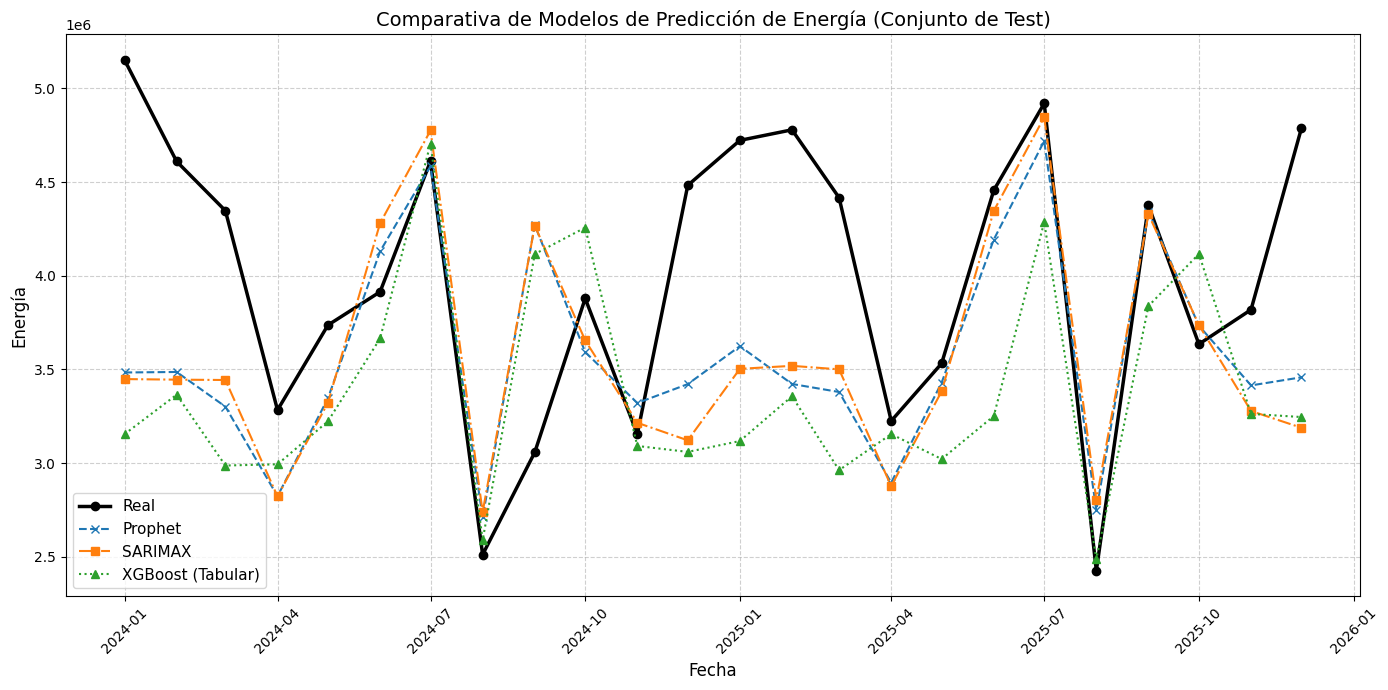

In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

y_true = df_test['Energia'].values

# Función auxiliar para calcular métricas
def evaluar(y_true, y_pred, nombre):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {'Modelo': nombre, 'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape}

# Consolidar resultados
tabla_resultados = pd.DataFrame([
    evaluar(y_true, pred_prophet, 'Prophet'),
    evaluar(y_true, pred_sarimax, 'SARIMAX'),
    evaluar(y_true, preds_xgb, 'XGBoost')
])

print("--- TABLA COMPARATIVA DE RENDIMIENTO ---")
print(tabla_resultados.to_string(index=False))

# Gráfica comparativa
plt.figure(figsize=(14, 7))
plt.plot(df_test['Fecha'], y_true, label='Real', color='black', linewidth=2.5, marker='o')
plt.plot(df_test['Fecha'], pred_prophet, label='Prophet', linestyle='--', marker='x')
plt.plot(df_test['Fecha'], pred_sarimax, label='SARIMAX', linestyle='-.', marker='s')
plt.plot(df_test['Fecha'], preds_xgb, label='XGBoost (Tabular)', linestyle=':', marker='^')

plt.title('Comparativa de Modelos de Predicción de Energía (Conjunto de Test)', fontsize=14)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Energía', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Entrenamiento modelo Final

In [60]:
# Preparar datos para Prophet
df_prophet_long = df_long[['Fecha', 'Energia']].rename(columns={'Fecha': 'ds', 'Energia': 'y'})

# Inicializar y entrenar el modelo
model_prophet = Prophet()
model_prophet.fit(df_prophet_long)



INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


# Descargar modelo

In [61]:
import pickle

# Suponiendo que ya has ejecutado esto:
# model_prophet = Prophet()
# model_prophet.fit(df_prophet_long)

# Guardar el modelo en un archivo .pkl
with open('modelo_prophet_energia.pkl', 'wb') as f:
    pickle.dump(model_prophet, f)

print("¡Modelo guardado con éxito!")

¡Modelo guardado con éxito!
